In [1]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import os

folder_path = "/content/drive/MyDrive/buildings"
os.makedirs(folder_path, exist_ok=True)

print("Buildings folder created successfully!")

Buildings folder created successfully!


In [19]:
import os

folder_path = "/content/drive/MyDrive/buildings"

images = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Total images:", len(images))
print("First 10 images:", images[:10])

Total images: 101
First 10 images: ['building_1.jpg', 'building_2.jpg', 'building_3.jpg', 'building_4.jpg', 'building_5.jpg', 'building_6.jpg', 'building_7.jpg', 'building_8.jpg', 'building_9.jpg', 'building_10.jpg']


Total images: 101


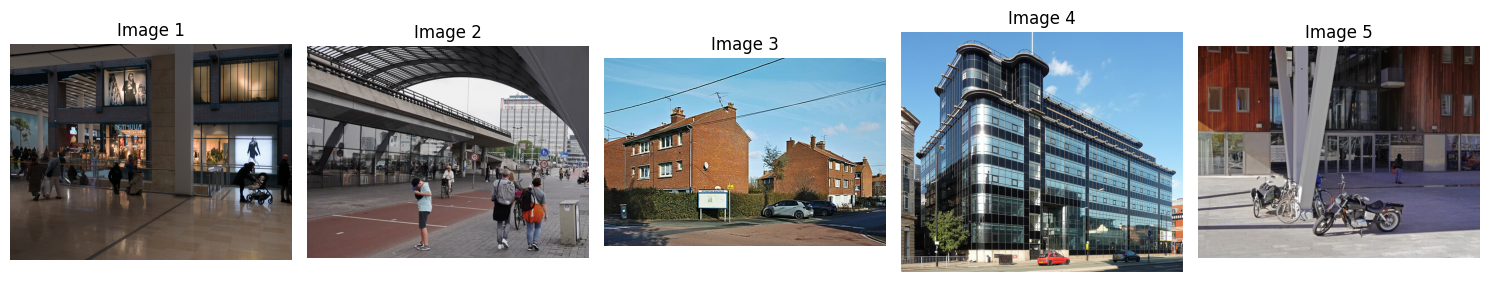

In [20]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

folder_path = "/content/drive/MyDrive/buildings"

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Total images:", len(images))

# Display the first 5 images
plt.figure(figsize=(15, 8))

for i in range(min(5, len(images))):
    image_path = os.path.join(folder_path, images[i])
    img = mpimg.imread(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import numpy as np
import matplotlib.image as mpimg
import os

folder_path = "/content/drive/MyDrive/buildings"

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

for i in range(5):
    image_path = os.path.join(folder_path, images[i])
    img = mpimg.imread(image_path)
    img_array = np.array(img)

    print(f"Image {i + 1}")
    print("Dimensions:", img_array.shape)
    print("Data type:", img_array.dtype)
    print("Minimum pixel value:", np.min(img_array))
    print("Maximum pixel value:", np.max(img_array))
    print("-" * 30)

Image 1
Dimensions: (3189, 4179, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
------------------------------
Image 2
Dimensions: (375, 500, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
------------------------------
Image 3
Dimensions: (333, 500, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
------------------------------
Image 4
Dimensions: (545, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
------------------------------
Image 5
Dimensions: (375, 500, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
------------------------------


Original dimensions: (3189, 4179, 3)
Resized dimensions: (200, 200, 3)


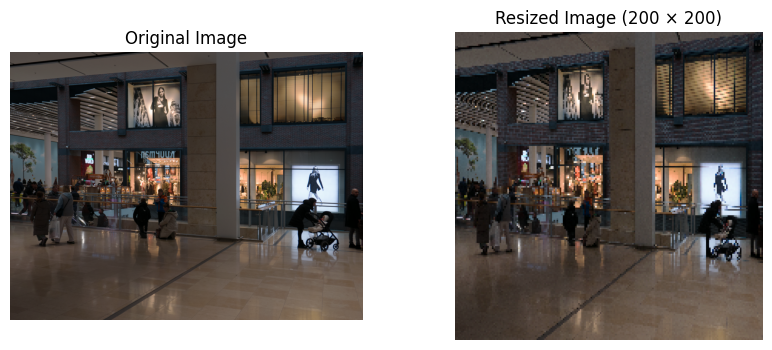

In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

folder_path = "/content/drive/MyDrive/buildings"

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

# Select the first image
img = mpimg.imread(os.path.join(folder_path, images[0]))

# Resize using NumPy indexing
height, width = img.shape[:2]
new_size = 200

row_indices = np.linspace(0, height - 1, new_size).astype(int)
col_indices = np.linspace(0, width - 1, new_size).astype(int)

resized_img = img[row_indices[:, None], col_indices]

print("Original dimensions:", img.shape)
print("Resized dimensions:", resized_img.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img)
plt.title("Resized Image (200 × 200)")
plt.axis("off")

plt.show()

In [23]:
import os
import matplotlib.image as mpimg
import numpy as np
import matplotlib.pyplot as plt

folder_path = "/content/drive/MyDrive/buildings"
output_path = "/content/drive/MyDrive/buildings_resized"

os.makedirs(output_path, exist_ok=True)

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

for filename in images:
    img = mpimg.imread(os.path.join(folder_path, filename))

    height, width = img.shape[:2]

    row_indices = np.linspace(0, height - 1, 200).astype(int)
    col_indices = np.linspace(0, width - 1, 200).astype(int)

    resized_img = img[row_indices[:, None], col_indices]

    # Save resized image
    output_file = os.path.join(
        output_path, os.path.splitext(filename)[0] + ".png"
    )
    plt.imsave(output_file, resized_img)

print("Original images:", len(images))
print("Resized images:", len(os.listdir(output_path)))
print("New dimensions:", resized_img.shape)
print("Saved in:", output_path)

Original images: 101
Resized images: 101
New dimensions: (200, 200, 3)
Saved in: /content/drive/MyDrive/buildings_resized


In [24]:
import os
import numpy as np
import matplotlib.image as mpimg

folder_path = "/content/drive/MyDrive/buildings_resized"

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith(".png")
])

brightness = []

for filename in images:
    img = mpimg.imread(os.path.join(folder_path, filename))
    brightness.append(np.mean(img[:, :, :3]))

brightness = np.array(brightness)

print("Images analyzed:", len(brightness))
print("Average brightness:", np.mean(brightness))
print("Brightest image value:", np.max(brightness))
print("Darkest image value:", np.min(brightness))
print("Brightness variation:", np.std(brightness))

Images analyzed: 101
Average brightness: 0.4475417
Brightest image value: 0.7480225
Darkest image value: 0.16929106
Brightness variation: 0.105590396


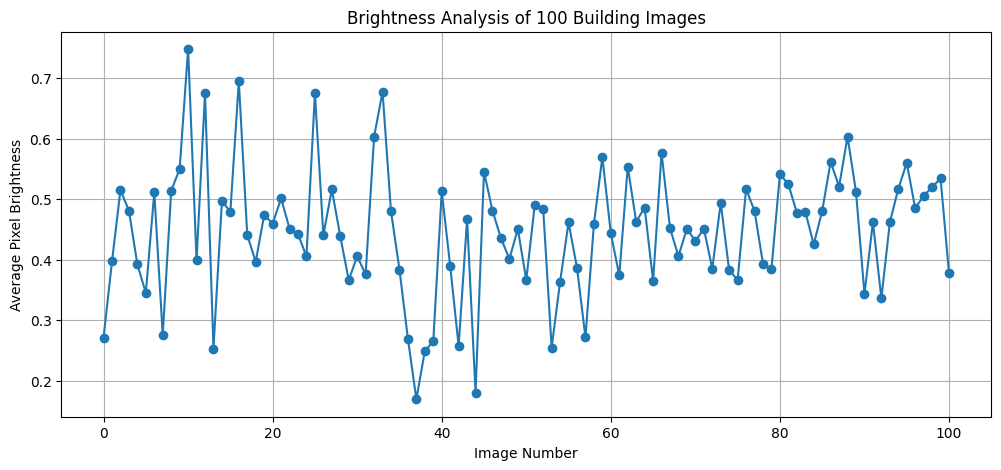

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(brightness, marker="o")
plt.title("Brightness Analysis of 100 Building Images")
plt.xlabel("Image Number")
plt.ylabel("Average Pixel Brightness")
plt.grid(True)
plt.show()

Images analyzed: 101
Average Red: 0.4343778
Average Green: 0.4516147
Average Blue: 0.45660684


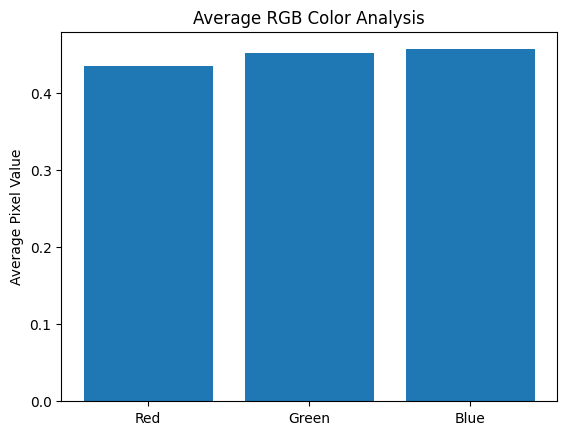

In [26]:
import os
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

folder_path = "/content/drive/MyDrive/buildings_resized"

images = sorted([
    f for f in os.listdir(folder_path)
    if f.lower().endswith(".png")
])

rgb_values = []

for filename in images:
    img = mpimg.imread(os.path.join(folder_path, filename))
    img = img[:, :, :3]
    rgb_values.append(np.mean(img, axis=(0, 1)))

rgb_values = np.array(rgb_values)

mean_rgb = np.mean(rgb_values, axis=0)

print("Images analyzed:", len(rgb_values))
print("Average Red:", mean_rgb[0])
print("Average Green:", mean_rgb[1])
print("Average Blue:", mean_rgb[2])

plt.bar(["Red", "Green", "Blue"], mean_rgb)
plt.title("Average RGB Color Analysis")
plt.ylabel("Average Pixel Value")
plt.show()

In [27]:
print("===== BUILDING IMAGE ANALYSIS =====")
print("Total images analyzed:", len(brightness))
print("Image size: 200 x 200 pixels")

print("\n--- Brightness Statistics ---")
print("Mean brightness:", round(float(np.mean(brightness)), 4))
print("Maximum brightness:", round(float(np.max(brightness)), 4))
print("Minimum brightness:", round(float(np.min(brightness)), 4))
print("Brightness variation:", round(float(np.std(brightness)), 4))

print("\n--- RGB Color Statistics ---")
print("Mean Red:", round(float(mean_rgb[0]), 4))
print("Mean Green:", round(float(mean_rgb[1]), 4))
print("Mean Blue:", round(float(mean_rgb[2]), 4))

===== BUILDING IMAGE ANALYSIS =====
Total images analyzed: 101
Image size: 200 x 200 pixels

--- Brightness Statistics ---
Mean brightness: 0.4475
Maximum brightness: 0.748
Minimum brightness: 0.1693
Brightness variation: 0.1056

--- RGB Color Statistics ---
Mean Red: 0.4344
Mean Green: 0.4516
Mean Blue: 0.4566


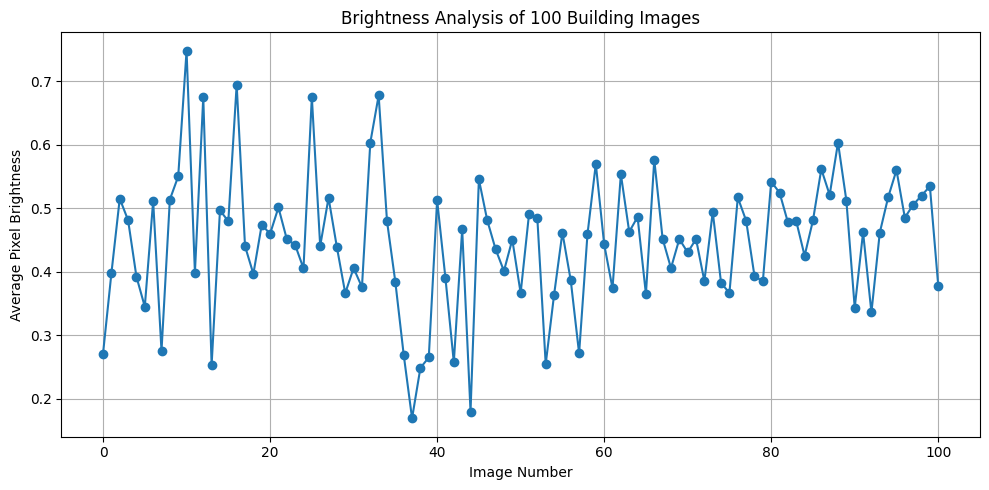

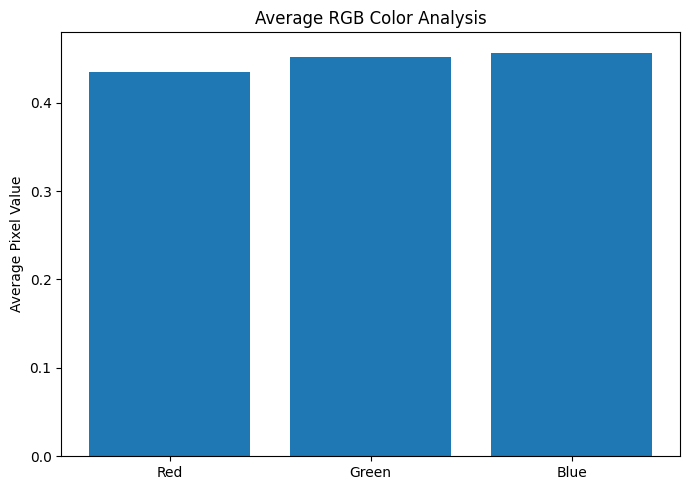

Graphs saved in: /content/drive/MyDrive/building_analysis_results


In [28]:
import os
import matplotlib.pyplot as plt

output_folder = "/content/drive/MyDrive/building_analysis_results"
os.makedirs(output_folder, exist_ok=True)

# Save brightness graph
plt.figure(figsize=(10, 5))
plt.plot(brightness, marker="o")
plt.title("Brightness Analysis of 100 Building Images")
plt.xlabel("Image Number")
plt.ylabel("Average Pixel Brightness")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_folder, "brightness_graph.png"))
plt.show()

# Save RGB graph
plt.figure(figsize=(7, 5))
plt.bar(["Red", "Green", "Blue"], mean_rgb)
plt.title("Average RGB Color Analysis")
plt.ylabel("Average Pixel Value")
plt.tight_layout()
plt.savefig(os.path.join(output_folder, "rgb_graph.png"))
plt.show()

print("Graphs saved in:", output_folder)

Total images analyzed: 101
Average brightness: 0.4475417
Brightest image value: 0.7480225
Darkest image value: 0.16929106


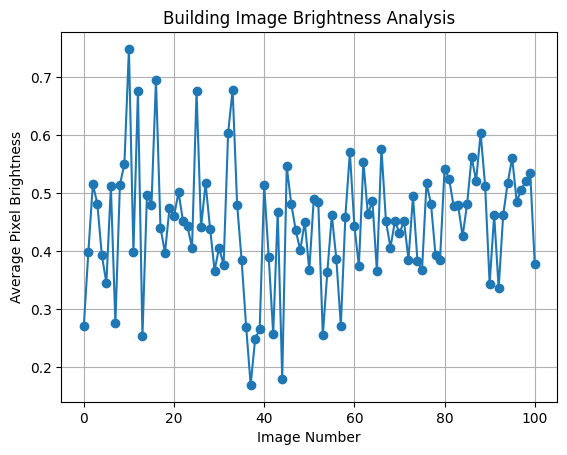

In [29]:
import os
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

class BuildingImageAnalysis:
    def __init__(self, folder_path):
        self.folder_path = folder_path
        self.images = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ])
        self.brightness_values = []

    def analyze_brightness(self):
        self.brightness_values = []

        for filename in self.images:
            path = os.path.join(self.folder_path, filename)
            img = mpimg.imread(path)
            img = np.array(img)

            if img.ndim == 3:
                img = img[:, :, :3]

            self.brightness_values.append(np.mean(img))

        self.brightness_values = np.array(self.brightness_values)

        print("Total images analyzed:", len(self.brightness_values))
        print("Average brightness:", np.mean(self.brightness_values))
        print("Brightest image value:", np.max(self.brightness_values))
        print("Darkest image value:", np.min(self.brightness_values))

    def plot_brightness(self):
        plt.plot(self.brightness_values, marker="o")
        plt.title("Building Image Brightness Analysis")
        plt.xlabel("Image Number")
        plt.ylabel("Average Pixel Brightness")
        plt.grid(True)
        plt.show()


folder_path = "/content/drive/MyDrive/buildings_resized"

building_project = BuildingImageAnalysis(folder_path)
building_project.analyze_brightness()
building_project.plot_brightness()

In [31]:
print("===== BUILDING IMAGE ANALYSIS PROJECT =====")
print("Total raw images: 101")
print("Resized image dimensions: 200 x 200 pixels")
print("Python class: Implemented")
print("NumPy analysis: Completed")
print("Matplotlib graphs: Completed")

print("\n===== CONCLUSION =====")
print("The project analyzed a dataset of building images.")
print("All images were resized to a common dimension.")
print("Brightness and RGB color statistics were calculated.")
print("Graphs were used to visualize the analysis results.")
print("This project demonstrates image preprocessing and")
print("basic numerical analysis using Python, NumPy and Matplotlib.")

===== BUILDING IMAGE ANALYSIS PROJECT =====
Total raw images: 100
Resized image dimensions: 200 x 200 pixels
Python class: Implemented
NumPy analysis: Completed
Matplotlib graphs: Completed

===== CONCLUSION =====
The project analyzed a dataset of building images.
All images were resized to a common dimension.
Brightness and RGB color statistics were calculated.
Graphs were used to visualize the analysis results.
This project demonstrates image preprocessing and
basic numerical analysis using Python, NumPy and Matplotlib.
